# 04. Inferential models

Tests H1 to H3 (and secondary outcomes) following Table 4 of the proposal. **Dummy data by default; nothing here is a finding until `DATA_DIR` points at real data.**

| Outcome | Primary model | Basis |
| :-- | :-- | :-- |
| T_find (H1) | linear mixed model on log time, participant random intercept | successful trials |
| E (H2) | Poisson GEE (negative-binomial if overdispersed), clustered on participant | successful trials |
| R (H3) | linear mixed model on log time | successful trials with E >= 1 |
| success | logistic GEE | all trials |
| T_clean, SEQ | linear mixed model | secondary |

All include a block-position term (block position and task pair are the same factor in this design). Omnibus pattern effect: Wald test; pairwise contrasts with Holm correction; reference pattern DH.

**Fallback rule (fixed in advance):** if the primary model is not estimable or did not converge, or its residuals fail Shapiro or Levene at p < .01, the decision uses the Friedman test (Wilcoxon follow-ups) instead. Both are always computed.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

DATA_DIR = ROOT / "data" / "dummy"      # <- point this at data/raw/<your export folder> for real data
OUT_DIR = ROOT / "outputs"

from IPython.display import Image, display
from pipeline.prepare import prepare
from pipeline.models import run_models
from pipeline.plots import make_model_figures

prep = prepare(DATA_DIR)
suite = run_models(prep)
suite.write(OUT_DIR)
paths = make_model_figures(suite, OUT_DIR)

## Decision table
One row per outcome. `decision_source` says which test the decision uses; `flag_reasons` explains any fallback. `omnibus_p` is the primary model; `friedman_p` is the fallback.

In [2]:
cols = ['outcome','hypothesis','primary_model','n_obs','omnibus_p','friedman_p','flagged_for_fallback','decision_source','decision_p','significant']
suite.summary()[cols].round(4)

,outcome,hypothesis,primary_model,n_obs,omnibus_p,friedman_p,flagged_for_fallback,decision_source,decision_p,significant
0,T_find,H1,linear mixed model on log T_find,85,0.0000,0.0020,False,primary,0.0000,True
1,E,H2,Poisson GEE (dispersion 1.16),85,0.0032,0.1264,False,primary,0.0032,True
2,R,H3,linear mixed model on log R,31,0.0142,NaN,True,primary,0.0142,True
3,success,,logistic GEE,89,NaN,0.3679,True,fallback,0.3679,False
4,T_clean,,linear mixed model on log T_clean,85,0.0000,0.0016,False,primary,0.0000,True
5,SEQ,,linear mixed model (rating treated as continuous),89,0.1315,0.2050,True,fallback,0.2050,False


In [3]:
suite.summary()[['outcome','flag_reasons','notes']]

,outcome,flag_reasons,notes
0,T_find,,
1,E,,
2,R,unequal residual spread across patterns (Leven...,participant variance estimated at ~0 (singular...
3,success,primary model not estimable: complete separati...,complete separation: every trial in pattern(s)...
4,T_clean,,
5,SEQ,residuals non-normal (Shapiro p = 0.0000),participant variance estimated at ~0 (singular...


## Pairwise contrasts and effect sizes
`effect` is a ratio of geometric means (times), a rate ratio (E) or an odds ratio (success) for the primary model, and a median paired ratio/difference for the Friedman fallback. Read `MM vs DH` as MM relative to DH. Only report pairwise results when the omnibus test is significant.

In [4]:
pw = suite.pairwise()
pw[pw.is_decision_source].drop(columns='is_decision_source').round(3)

,outcome,source,contrast,effect,ci_low,ci_high,p_raw,p_holm,significant_holm,effect_type
0,T_find,primary,MM vs DH,0.774,0.642,0.934,0.007,0.015,True,ratio of geometric means
1,T_find,primary,ND vs DH,1.275,1.063,1.529,0.009,0.015,True,ratio of geometric means
2,T_find,primary,ND vs MM,1.646,1.370,1.978,0.000,0.000,True,ratio of geometric means
6,E,primary,MM vs DH,0.724,0.347,1.512,0.390,0.390,False,rate ratio
7,E,primary,ND vs DH,1.885,1.078,3.297,0.026,0.052,False,rate ratio
8,E,primary,ND vs MM,2.603,1.395,4.859,0.003,0.008,True,rate ratio
12,R,primary,MM vs DH,0.560,0.326,0.962,0.036,0.071,False,ratio of geometric means
13,R,primary,ND vs DH,1.073,0.660,1.746,0.776,0.776,False,ratio of geometric means
14,R,primary,ND vs MM,1.915,1.221,3.004,0.005,0.014,True,ratio of geometric means
15,success,fallback,MM vs DH,0.000,NaN,NaN,1.000,1.000,False,median paired difference


### All primary and fallback contrasts

In [5]:
pw.drop(columns='is_decision_source').round(3)

,outcome,source,contrast,effect,ci_low,ci_high,p_raw,p_holm,significant_holm,effect_type
0,T_find,primary,MM vs DH,0.774,0.642,0.934,0.007,0.015,True,ratio of geometric means
1,T_find,primary,ND vs DH,1.275,1.063,1.529,0.009,0.015,True,ratio of geometric means
2,T_find,primary,ND vs MM,1.646,1.370,1.978,0.000,0.000,True,ratio of geometric means
3,T_find,fallback,MM vs DH,0.718,NaN,NaN,0.073,0.073,False,median paired ratio
4,T_find,fallback,ND vs DH,1.151,NaN,NaN,0.012,0.025,True,median paired ratio
5,T_find,fallback,ND vs MM,1.672,NaN,NaN,0.000,0.001,True,median paired ratio
6,E,primary,MM vs DH,0.724,0.347,1.512,0.390,0.390,False,rate ratio
7,E,primary,ND vs DH,1.885,1.078,3.297,0.026,0.052,False,rate ratio
8,E,primary,ND vs MM,2.603,1.395,4.859,0.003,0.008,True,rate ratio
9,E,fallback,MM vs DH,0.000,NaN,NaN,0.469,0.469,False,median paired difference


## Sensitivity analyses
Do the conclusions hold when block 1 is dropped, when familiarity and prior use are added, and when failures are treated as censored (Cox model)? `agrees_with_primary` compares significance only. Disagreement is a limitation to report.

In [6]:
suite.sensitivity[['outcome','analysis','n_obs','omnibus_p','significant','agrees_with_primary','note']].round(4)

,outcome,analysis,n_obs,omnibus_p,significant,agrees_with_primary,note
0,T_find,primary model,85,0.0000,True,True,
1,T_find,excluding block position 1,56,0.0001,True,True,
2,T_find,+ familiarity and prior use,85,0.0000,True,True,
3,E,primary model,85,0.0032,True,True,
4,E,excluding block position 1,56,0.0631,False,False,
5,E,+ familiarity and prior use,85,0.0020,True,True,
6,R,primary model,31,0.0142,True,True,participant variance estimated at ~0 (singular...
7,R,excluding block position 1,19,0.1488,False,False,optimizer default did not converge; optimizer ...
8,R,+ familiarity and prior use,31,0.0148,True,True,
9,T_find,"Cox model, failures censored at trial end",89,0.0145,True,True,


## Preference ranking (secondary)

In [7]:
pf = suite.preference
print(f'Friedman chi2 = {pf.chi2:.2f}, p = {pf.p:.3f}, Kendall W = {pf.kendall_w:.2f}, n = {pf.n_participants}')
pf.pairwise.round(3)

Friedman chi2 = 4.93, p = 0.085, Kendall W = 0.16, n = 15


,contrast,effect,ci_low,ci_high,p_raw,p_holm,significant_holm
0,MM vs DH,-1.0,NaN,NaN,0.079,0.159,False
1,ND vs DH,-1.0,NaN,NaN,0.040,0.119,False
2,ND vs MM,1.0,NaN,NaN,0.788,0.788,False


## Figures

### F12: pairwise effect sizes
Filled dot = significant after Holm correction. If an interval crosses 1, that pair is not distinguishable.

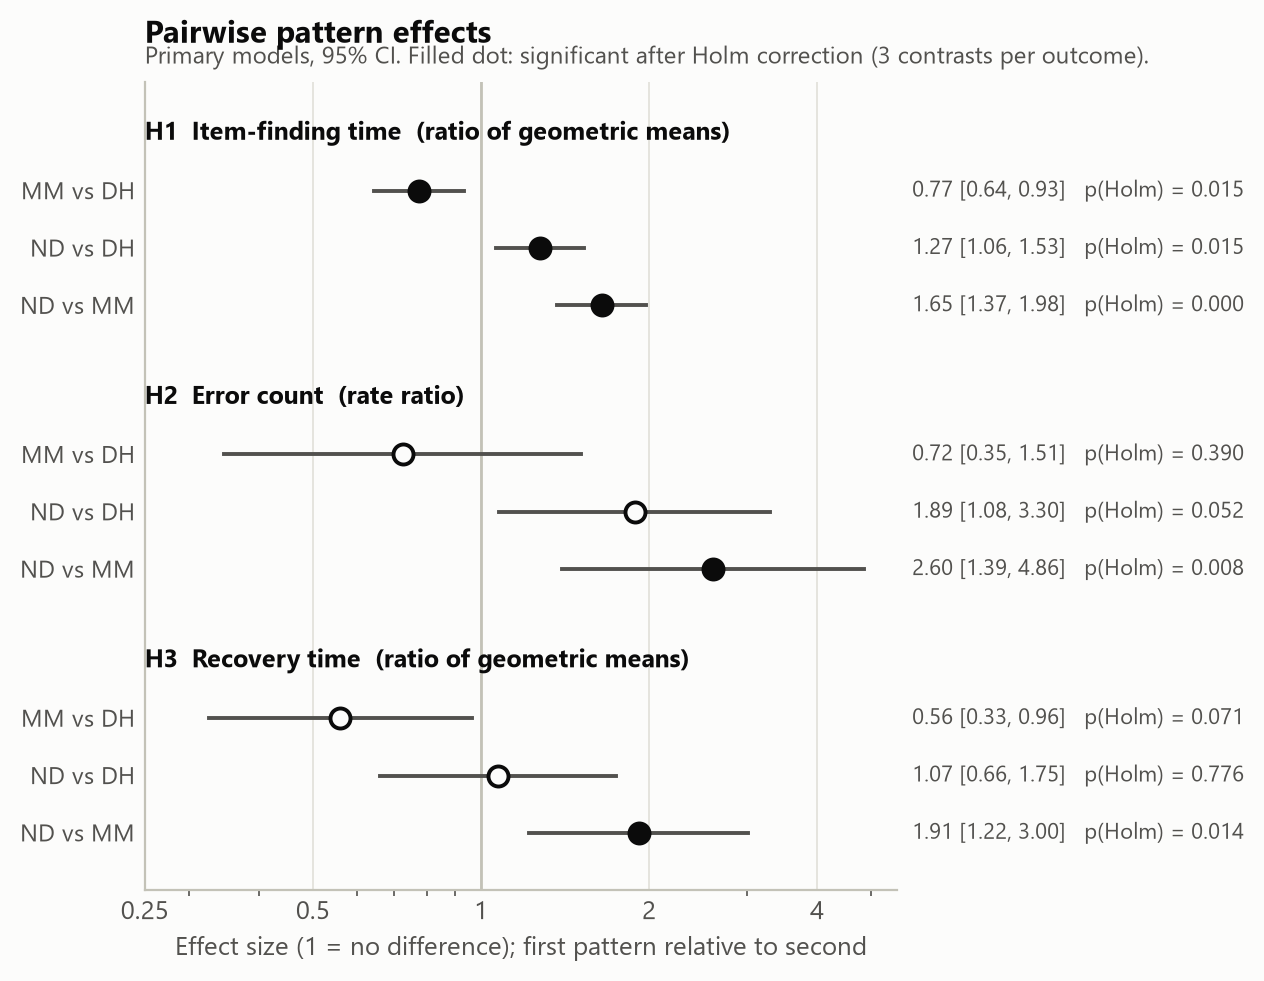

In [8]:
display(Image(filename=str(paths['F12_pairwise_effects'])))

### F11: model diagnostics
Q-Q points should follow the line; residuals should show no funnel or pattern against fitted values. Strong departures trigger the fallback.

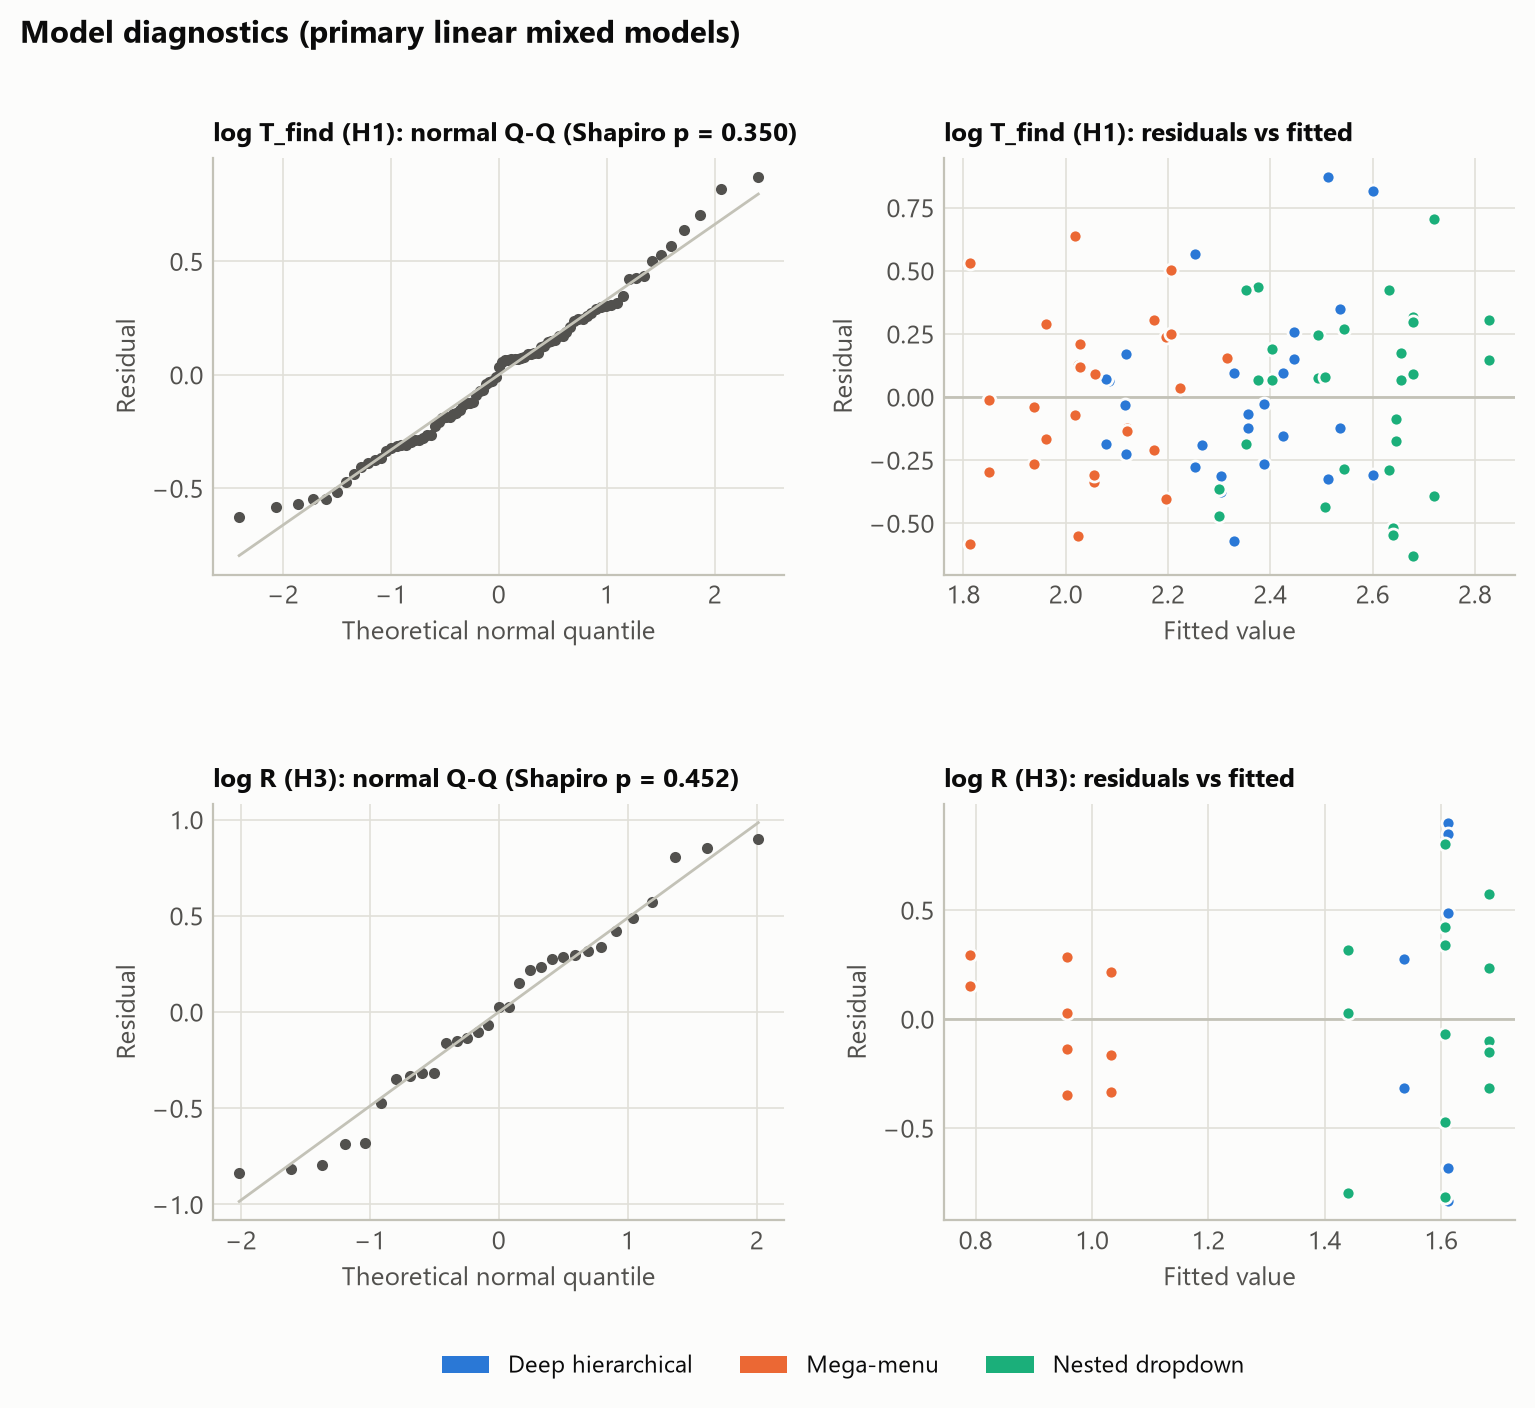

In [9]:
display(Image(filename=str(paths['F11_model_diagnostics'])))

## Reading these results honestly
- With N = 15 (30 trials per pattern) power is limited: "not significant" means *not detected*, not *no difference*.
- GEE effects are population-averaged, not participant-specific (a deviation from Table 4's mixed models).
- Block position and task pair are aliased, so a block effect may be learning or task difficulty.
- Failures are excluded from the time and error models; check the sensitivity table and the success rates.
- R uses only trials with errors, so n is small; check `n_obs` before interpreting it.